# Visualizing proportions

**Enda Hughes · DATA 110 · Fall 2026 · Week 10**


## Setup

The notebook reads local CSV copies when available and otherwise loads the course datasets from GitHub.


In [1]:
import csv
from html import escape
from math import cos, pi, sin
from pathlib import Path
from urllib.request import urlopen

course_folder = "https://raw.githubusercontent.com/Reben80/Data110-Fall2026-CRN21802/main/dataset/"

def load_csv(filename):
    local_file = Path(filename)
    if local_file.is_file():
        text = local_file.read_text(encoding="utf-8-sig")
    else:
        with urlopen(course_folder + filename) as response:
            text = response.read().decode("utf-8-sig")
    return list(csv.DictReader(text.splitlines()))

class Chart:
    def __init__(self, title, width=720, height=365):
        self.parts = [
            f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">',
            f'<rect width="{width}" height="{height}" fill="white"/>',
            '<g font-family="Arial, sans-serif" fill="#182636">'
        ]
        self.text(width / 2, 28, title, size=19)

    def text(self, x, y, label, size=12, anchor="middle", transform=""):
        self.parts.append(
            f'<text x="{x}" y="{y}" font-size="{size}" text-anchor="{anchor}" '
            f'transform="{transform}">{escape(str(label))}</text>'
        )

    def line(self, x1, y1, x2, y2, color="#263746", dashed=False):
        dash = ' stroke-dasharray="7 5"' if dashed else ""
        self.parts.append(
            f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="{color}"{dash}/>'
        )

    def rect(self, x, y, width, height, color):
        self.parts.append(
            f'<rect x="{x}" y="{y}" width="{width}" height="{height}" fill="{color}"/>'
        )

    def _repr_svg_(self):
        return "".join(self.parts) + "</g></svg>"

def bar_axes(chart, label, maximum, step, right=690):
    bottom = 280
    scale = 220 / maximum
    for tick in range(0, maximum + 1, step):
        y = bottom - tick * scale
        chart.line(65, y, right, y, "#dbe3ea")
        chart.text(56, y + 4, tick, anchor="end")
    chart.line(65, 60, 65, bottom)
    chart.line(65, bottom, right, bottom)
    chart.text(18, 170, label, transform="rotate(-90 18 170)")
    return bottom, scale

def add_legend(chart, entries, start, spacing):
    for index, (label, color) in enumerate(entries):
        x = start + index * spacing
        chart.rect(x, 332, 13, 13, color)
        chart.text(x + 18, 343, label, anchor="start")


## The parliament

One row is one party in the 8th German Bundestag, 1976–1980.

- `party` is CDU/CSU, SPD, or FDP.
- `seats` is the number of seats. The three numbers add to 496.


In [2]:
bundestag = load_csv("bundestag.csv")
for party in bundestag:
    party["seats"] = int(party["seats"])
bundestag


[{'party': 'CDU/CSU', 'seats': 243},
 {'party': 'SPD', 'seats': 214},
 {'party': 'FDP', 'seats': 39}]

## A color for each party

A dictionary pairs each party with one color. Blue is CDU/CSU, gold is SPD, and green is FDP. The colors name the parties. They are not a measure of the seats.


In [3]:
party_colors = {"CDU/CSU": "#0072B2", "SPD": "#E69F00", "FDP": "#009E73"}


## 1. A pie

**Exercise.** Draw a pie of `bundestag["seats"]`. Use the party names as the labels, and use `party_colors` for the slices.


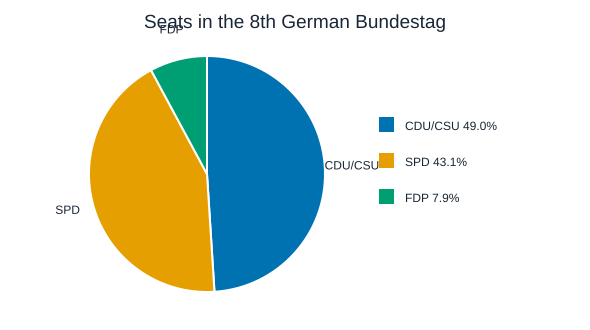

In [4]:
pie = Chart("Seats in the 8th German Bundestag", width=590, height=330)
total_seats = sum(party["seats"] for party in bundestag)
center_x, center_y, radius = 207, 174, 118
angle = -pi / 2

for index, party in enumerate(bundestag):
    fraction = party["seats"] / total_seats
    end = angle + 2 * pi * fraction
    x1, y1 = center_x + radius * cos(angle), center_y + radius * sin(angle)
    x2, y2 = center_x + radius * cos(end), center_y + radius * sin(end)
    color = party_colors[party["party"]]
    large_arc = int(fraction > 0.5)
    pie.parts.append(
        f'<path d="M {center_x} {center_y} L {x1} {y1} '
        f'A {radius} {radius} 0 {large_arc} 1 {x2} {y2} Z" '
        f'fill="{color}" stroke="white" stroke-width="2"/>'
    )
    middle = (angle + end) / 2
    pie.text(center_x + 145 * cos(middle), center_y + 145 * sin(middle),
             party["party"])
    y = 130 + 36 * index
    pie.rect(379, y - 13, 15, 15, color)
    pie.text(405, y, f'{party["party"]}   {fraction:.1%}', anchor="start")
    angle = end

pie


## 2. Side-by-side bars

**Exercise.** Draw one bar per party. Put `party` on the horizontal axis and `seats` on the vertical axis. Use `party_colors` again. Label the vertical axis `seats`.


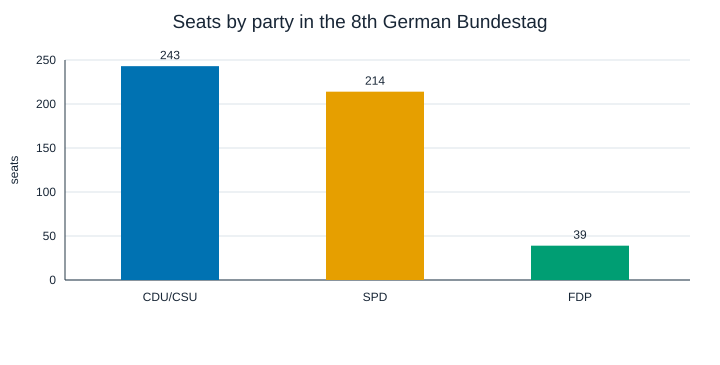

In [5]:
bars = Chart("Seats by party in the 8th German Bundestag")
bottom, scale = bar_axes(bars, "seats", 250, 50)

for index, party in enumerate(bundestag):
    name, seats = party["party"], party["seats"]
    x = 170 + index * 205
    height = seats * scale
    bars.rect(x - 49, bottom - height, 98, height, party_colors[name])
    bars.text(x, bottom + 21, name)
    bars.text(x, bottom - height - 7, seats)

bars


## 3. The percent

**Exercise.** Add a column named `percent`. Divide `seats` by the sum of `seats`, multiply by 100, and keep one decimal place. Then show the table.


In [6]:
for party in bundestag:
    party["percent"] = round(party["seats"] / total_seats * 100, 1)

print(f'{"Party":<10} {"Seats":>5} {"Percent":>8}')
for party in bundestag:
    print(f'{party["party"]:<10} {party["seats"]:>5} {party["percent"]:>8.1f}')


Party      Seats  Percent
CDU/CSU      243     49.0
SPD          214     43.1
FDP           39      7.9


## The companies

One row is one company in one year. The shares are made up.

- `company` is A, B, C, D, or E.
- `year` is 2015, 2016, or 2017.
- `percent` is that company's share of the market. In each year the five percents add to 100.

Blue is A, sky blue is B, green is C, gold is D, and vermillion is E.


In [7]:
share = load_csv("marketshare.csv")
company_colors = {
    "A": "#0072B2",
    "B": "#56B4E9",
    "C": "#009E73",
    "D": "#E69F00",
    "E": "#D55E00",
}
for row in share:
    row["year"] = int(row["year"])
    row["percent"] = int(row["percent"])
share[:5]


[{'percent': 17, 'company': 'A', 'year': 2015},
 {'percent': 18, 'company': 'B', 'year': 2015},
 {'percent': 20, 'company': 'C', 'year': 2015},
 {'percent': 22, 'company': 'D', 'year': 2015},
 {'percent': 23, 'company': 'E', 'year': 2015}]

## 4. Five bars beside each year

**Exercise.** Draw the market shares as side-by-side bars. Each year has five bars, one per company, and every bar starts at zero.


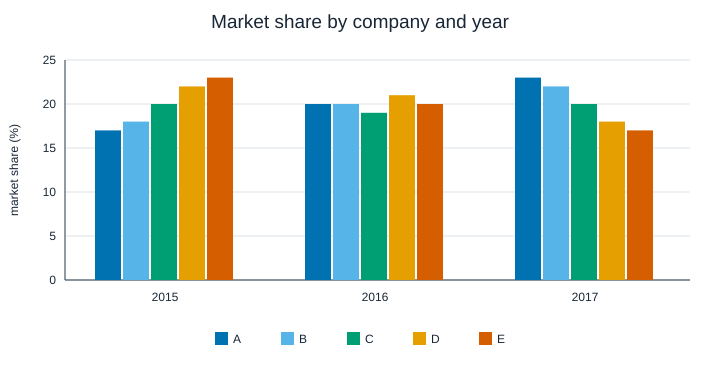

In [8]:
market = Chart("Market share by company and year")
bottom, scale = bar_axes(market, "market share (%)", 25, 5)
years = sorted({row["year"] for row in share})
bar_width = 28

for index, (company, color) in enumerate(company_colors.items()):
    company_rows = sorted(
        (row for row in share if row["company"] == company),
        key=lambda row: row["year"],
    )
    for year_index, row in enumerate(company_rows):
        center = 165 + year_index * 210
        x = center + (index - 2) * bar_width - bar_width / 2
        height = row["percent"] * scale
        market.rect(x, bottom - height, bar_width - 2, height, color)

for year_index, year in enumerate(years):
    market.text(165 + year_index * 210, bottom + 21, year)

add_legend(market, company_colors.items(), start=215, spacing=66)
market


## Rwanda

One row is one year of the Rwandan parliament, from 1997 to 2016.

- `year` is the year.
- `women` is the percent of seats held by women.
- `men` is the percent held by men. The two columns add to 100.

The percentage stays the same for several years, then jumps.


In [9]:
rwanda = load_csv("rwanda.csv")
for row in rwanda:
    row["year"] = int(row["year"])
    row["women"] = float(row["women"])
    row["men"] = float(row["men"])
rwanda[:5]


[{'year': 1997, 'women': 17.1, 'men': 82.9},
 {'year': 1998, 'women': 17.1, 'men': 82.9},
 {'year': 1999, 'women': 17.1, 'men': 82.9},
 {'year': 2000, 'women': 25.7, 'men': 74.3},
 {'year': 2001, 'women': 25.7, 'men': 74.3}]

## 5. Stack women and men

**Exercise.** Draw a stacked bar for each year. Women are on the bottom, in `#D55E00`. Men are on top, in `#0072B2`. Draw a dashed line at 50.


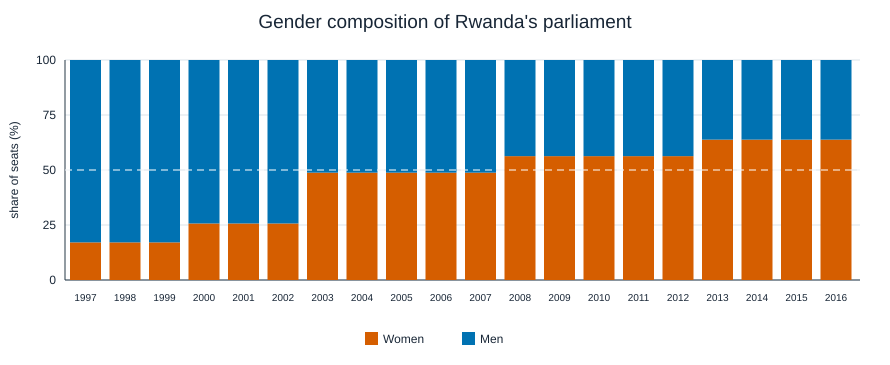

In [10]:
parliament = Chart("Gender composition of Rwanda's parliament", width=890)
bottom, scale = bar_axes(parliament, "share of seats (%)", 100, 25, right=860)
women_color = "#D55E00"
men_color = "#0072B2"

for index, row in enumerate(rwanda):
    x = 70 + index * 39.5
    women_height = row["women"] * scale
    men_height = row["men"] * scale
    parliament.rect(x, bottom - women_height, 31, women_height, women_color)
    parliament.rect(x, bottom - women_height - men_height, 31, men_height, men_color)
    parliament.text(x + 15.5, bottom + 21, row["year"], size=10)

halfway = bottom - 50 * scale
parliament.line(65, halfway, 860, halfway, "white", dashed=True)
add_legend(parliament, [("Women", women_color), ("Men", men_color)],
           start=365, spacing=97)
parliament
